<a href="https://colab.research.google.com/github/elonsobrevilla06-byte/InjectionsIdentifier_XGBoost/blob/main/InjectionIdentifier_XGBoost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import kagglehub
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import xgboost as xgb
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import OneHotEncoder
import seaborn as sns

# **1.) Acquiring Data**

In [ ]:
path = kagglehub.dataset_download("sajid576/sql-injection-dataset")
df = pd.read_csv(f"{path}/Modified_SQL_Dataset.csv")

100%|██████████| 425k/425k [00:00<00:00, 79.0MB/s]

Extracting files...


### - **Understanding the Data**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30919 entries, 0 to 30918
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Query   30919 non-null  object
 1   Label   30919 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 483.2+ KB


In [ ]:
df.describe()

,Label
count,30919.000000
mean,0.368123
std,0.482303
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


In [ ]:
df.head()

,Query,Label
0,""" or pg_sleep ( __TIME__ ) --",1
1,create user name identified by pass123 tempora...,1
2,AND 1 = utl_inaddr.get_host_address ( ...,1
3,select * from users where id = '1' or @ @1 ...,1
4,"select * from users where id = 1 or 1#"" ( ...",1


In [ ]:
df.columns

Index(['Query', 'Label'], dtype='object')

# **2.) Data Cleaning**

In [ ]:
df.isna().any(axis = None)

np.False_

In [ ]:
df.isna().sum()

,0
Query,0
Label,0


In [ ]:
for col in df.columns:
  print(f"\n--{col}--")
  print(df[col].unique())


--Query--
['" or pg_sleep  (  __TIME__  )  --'
 'create user name identified by pass123 temporary tablespace temp default tablespace users;'
 " AND 1  =  utl_inaddr.get_host_address   (    (   SELECT DISTINCT  (  table_name  )   FROM   (  SELECT DISTINCT  (  table_name  )  , ROWNUM AS LIMIT FROM sys.all_tables  )   WHERE LIMIT  =  5   )    )    AND 'i'  =  'i"
 ... 'SELECT wide ( s )  FROM west'
 'SELECT * FROM  ( SELECT slide FROM breath ) ' 'SELECT TOP 3 * FROM race']

--Label--
[1 0]


Index(['Query', 'Label'], dtype='object')


<Axes: xlabel='Label'>

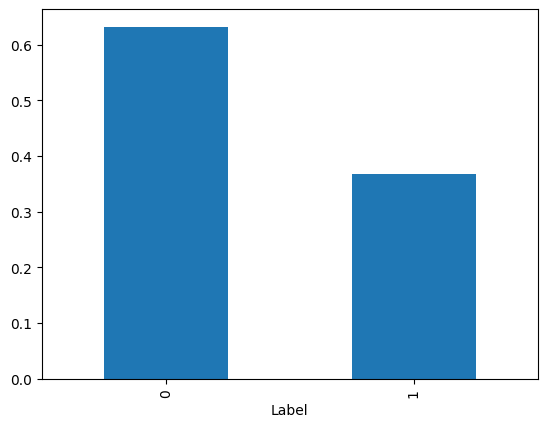

In [ ]:
print(df.columns)
df["Label"].value_counts(normalize = True).plot(kind = 'bar')

<Axes: title={'center': 'Sql Injection or No'}>

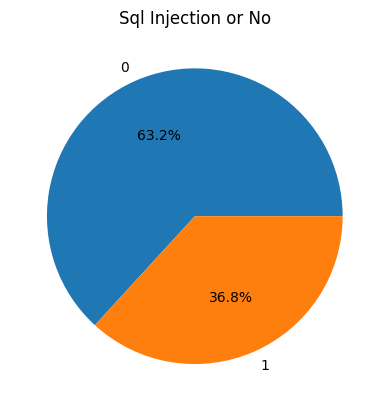

In [ ]:
df['Label'].value_counts(normalize = True).plot(
    kind = 'pie',
    title = "Sql Injection or No",
    ylabel = '',
    autopct = '%1.1f%%'
    )

In [ ]:
df.columns

Index(['Query', 'Label'], dtype='object')

In [ ]:
df.Query

,Query
0,""" or pg_sleep ( __TIME__ ) --"
1,create user name identified by pass123 tempora...
2,AND 1 = utl_inaddr.get_host_address ( ...
3,select * from users where id = '1' or @ @1 ...
4,"select * from users where id = 1 or 1#"" ( ..."
...,...
30914,DELETE FROM door WHERE grow = 'small'
30915,DELETE FROM tomorrow
30916,SELECT wide ( s ) FROM west
30917,SELECT * FROM ( SELECT slide FROM breath )


In [ ]:
print(df["Label"].value_counts())

Label
0    19537
1    11382
Name: count, dtype: int64


# **3.) Exploratory Data Analysis**

In [ ]:
df.duplicated().sum()
df[df.duplicated()]

,Query,Label
866,#NAME?,1
13532,#NAME?,0
14626,1.94E+15,0
15635,#NAME?,0
17255,1.86E+15,0
17913,#NAME?,0
18233,#NAME?,0
18875,#NAME?,0
18961,7.75E+15,0
19328,26%,1


In [ ]:
print(f"Original Length: {len(df)}")


Original Length 30919


In [ ]:
df.drop_duplicates(inplace = True)

In [ ]:
print(f"Dropped Duplicagtes: {len(df)}")

Dropped Duplicagtes: 30907


# Training Model

In [ ]:
df.columns

Index(['Query', 'Label'], dtype='object')

In [ ]:
X = df["Query"]
y = df["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,y, test_size = 0.2, random_state = 42, stratify = y
)

categorical_cols = df["Query"]

print(categorical_cols)

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(2, 5)
    )),
    ("classifier", xgb.XGBClassifier(
        n_estimators=100,
        random_state=1,
        learning_rate=0.05
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy: ", accuracy_score(y_test, y_pred))



0                        " or pg_sleep  (  __TIME__  )  --
1        create user name identified by pass123 tempora...
2         AND 1  =  utl_inaddr.get_host_address   (    ...
3         select * from users where id  =  '1' or @ @1 ...
4         select * from users where id  =  1 or 1#"  ( ...
                               ...                        
30914                DELETE FROM door WHERE grow = 'small'
30915                                 DELETE FROM tomorrow
30916                         SELECT wide ( s )  FROM west
30917         SELECT * FROM  ( SELECT slide FROM breath ) 
30918                             SELECT TOP 3 * FROM race
Name: Query, Length: 30907, dtype: object
Accuracy:  0.9948236816564219


In [ ]:
print(f"Classification report: {classification_report(y_test, y_pred)}")

Classification report:               precision    recall  f1-score   support

           0       0.99      1.00      1.00      3906
           1       1.00      0.99      0.99      2276

    accuracy                           0.99      6182
   macro avg       1.00      0.99      0.99      6182
weighted avg       0.99      0.99      0.99      6182



<Axes: >

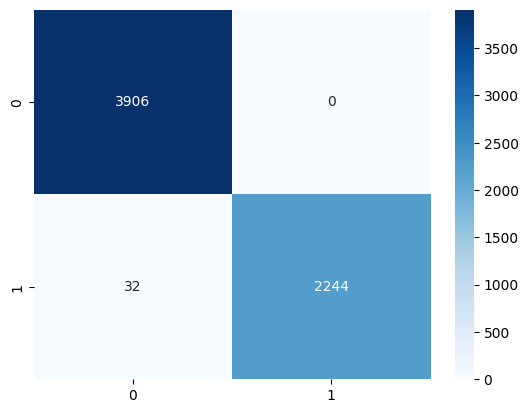

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels = model.classes_)
sns.heatmap(cm, annot = True, fmt = "d", cmap = "Blues",
            xticklabels = model.classes_,
            yticklabels = model.classes_
            )